# A/B tests

# Практические задания

### Данные датасета, которые необходимы в заданиях

| Поле | Описание | Для чего используется |
|------|----------|----------------------|
| `experiment_group` | Группа эксперимента: `A` или `B` | Деление пользователей на контрольную и тестовую группы |
| `review_strategy` | Название стратегии повторения | Описание различия между группами |
| `p_recall_ab` | Доля правильного воспоминания слова после применения стратегии | Основная числовая метрика для t-теста |
| `retention_7d` | Вернулся ли пользователь к обучению на 7-й день: `1` — да, `0` — нет | Метрика конверсии для хи-квадрат теста |

**Задание 1. Исследование данных и описательные статистики»**
1. Загрузи данные из файла `duolingo.csv`.
2. Выполни первичный осмотр данных:
    - Выведи размер датасета: количество строк и колонок.
    - Покажи первые 5 строк: `df.head()`.
    - Выведи названия колонок и типы данных.
    - Проверь пропущенные значения. 
3. Выбери целевую метрику для анализа: `p_recall_ab`.
4. Раздели данные на группы A и B по колонке.
5. Проверь баланс групп: укажи количество записей в каждой группе.
6. Посчитай описательную статистику через NumPy для каждой группы:
      - среднее;
      - медиану;
      - стандартное отклонение;
      - минимум и максимум;
      - 25-й и 75-й перцентили.
7. Рассчитай разницу между группами:
      - абсолютная разница средних;
      - относительная разница в процентах.
8. Сделай первичный вывод:
      - укажи, какая группа показывает большее значение;
      - попробуй объяснить, что это может значить для продукта.
9. Сохрани файл `project_8_task_1.ipynb` и загрузи его в папку src.

In [ ]:
import numpy as np
import pandas as pd

url = "/Users/user/Downloads/duolingo.csv"
df = pd.read_csv(url)
print(" Строки: ",len(df),"\n","Колонки: ",len(df.columns))
print("Перые 5 строк датасета:","\n",df.head(5))
print("Названия столбцов: ","\n",df.columns)
print("Типы данных: ","\n", df.dtypes)
print("наличие пропусков: ", df.isnull().any().any())

experiment_group_A = df[df['experiment_group']== 'A']
experiment_group_B = df[df['experiment_group'] =='B']
print("Количество записей в группе А:",len(experiment_group_A))
print("Количество записей в группе В:",len(experiment_group_B))

def statistics(name,data):
    print(f"среднее {name}: {np.mean(data['p_recall_ab']):.3f}")
    print(f"медианa {name}: {np.median(data['p_recall_ab']):.3f} ")
    print(f"стандартное отклонение {name}: {np.std(data['p_recall_ab']):.3f}")
    print(f"минимум и максимум {name}: {np.min(data['p_recall_ab'])} / {np.max(data['p_recall_ab']):.3f}")
    print(f"25-й перцентили: {name}: {np.percentile(data['p_recall_ab'], 25):.3f}")
    print(f"75-й перцентили: {name}: {np.percentile(data['p_recall_ab'], 75):.3f}")

statistics("группа А",experiment_group_A )
statistics("группа B",experiment_group_B )

mean_a = np.mean(experiment_group_A['p_recall_ab'])
mean_b = np.mean(experiment_group_B['p_recall_ab'])

abs_dif = mean_b - mean_a
rel_dif = (abs_dif / mean_a) * 100

print (f"абсолютная разница средних: {abs_dif:.3f}")
print(f"относительная разница в процентах: {rel_dif:.3f}")

print("Анализируя данные, было выявлено, что экспериментальная группа B показывает лучшие результаты по сравнению с группой A." ,"\n",
" Такой вывод можно сделать по значениям среднего и медианы, а также по тому, что стандартное отклонение у группы B меньше, " ,"\n",
"что говорит о большей стабильности результатов.")



**Задание 2. Проведение A/B-теста (t-тест)**
1. Проведи t-тест для метрики `p_recall_ab`.
2. Интерпретируй `p-value`:
      - сравни `p-value` с порогом значимости `0.05`;
      - сделай вывод: разница значима или может быть случайной.
3. Оцени размер эффекта:
      - рассчитай абсолютную разницу средних;
      - рассчитай относительную разницу в процентах;
      - оцени величину эффекта: малая `<5%`, умеренная `5–15%`, большая `>15%`.
4. Сформулируй итоговый вывод:
      - Укажи, какая группа показывает лучший результат.
      - Укажи, можно ли доверять этому результату.
5. Опционально визуализируй распределение:
      - построй гистограммы для групп A и B;
      - добавь вертикальные линии средних значений.
5. Сохрани файл `project_8_task_2.ipynb` и загрузи его в папку src. 

6.24545284793942e-222
Разница значима
Cреднее группы А 0.875
Cреднее группы B 0.895
Абсолютная разница:  0.01967246604127726
Величина эффекта:  2.24714041690632
Малая величина эффекта
Группа В показывает лучший результат


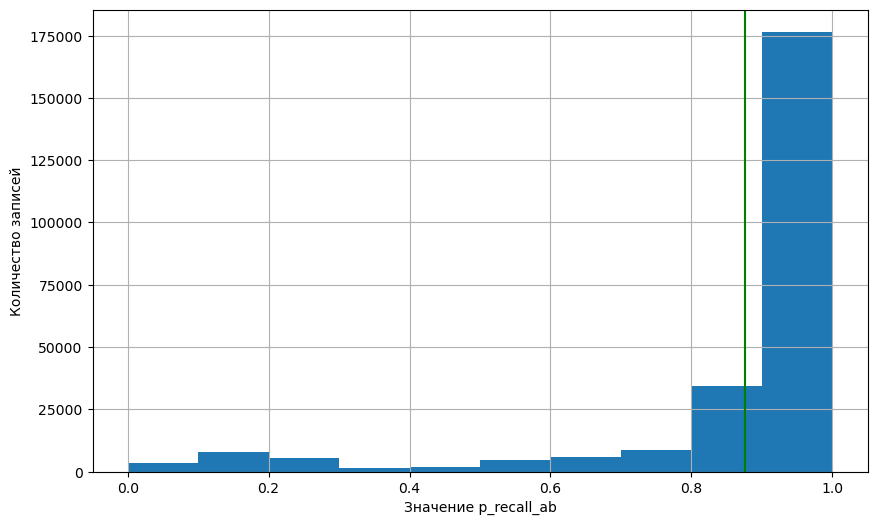

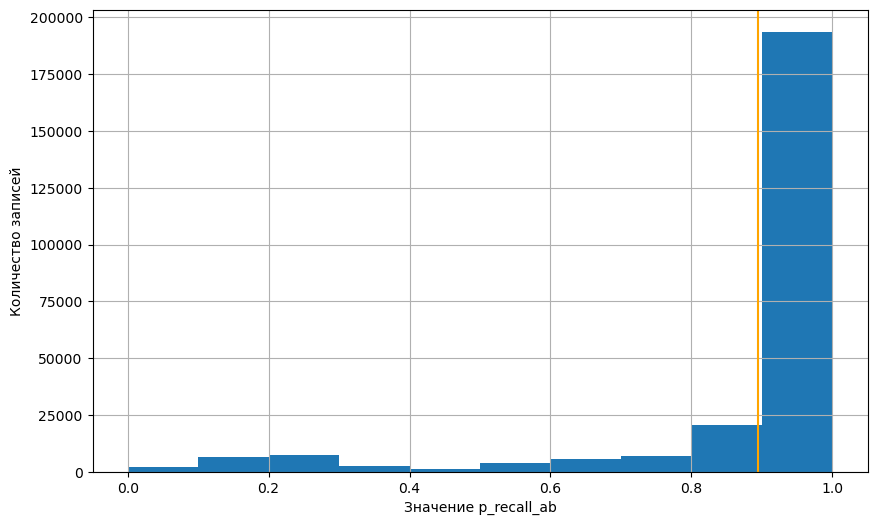

In [97]:
import numpy as np
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
import pandas as pd
url = "/Users/user/Downloads/duolingo.csv"
df = pd.read_csv(url)
experiment_group_A = df[df['experiment_group']== 'A']
experiment_group_B = df[df['experiment_group'] =='B']


t_stat,p_value = ttest_ind(experiment_group_A['p_recall_ab'],experiment_group_B['p_recall_ab'], equal_var=False)
print(p_value)

if p_value < 0.05:
    print("Разница значима")
else:
    print("Разница может быть слуайной")

mean_a = np.mean(experiment_group_A['p_recall_ab'])
mean_b = np.mean(experiment_group_B['p_recall_ab'])




print(f"Cреднее группы А {mean_a:.3f}")
print(f"Cреднее группы B {mean_b:.3f}")



abs_dif = mean_b - mean_a
effect = (abs_dif/mean_a ) * 100


print("Абсолютная разница: ", abs_dif)
print("Величина эффекта: ", effect)

if abs(effect) < 5:
    print("Малая величина эффекта")
elif abs(effect) > 5 and abs(effect) < 15:
    print("умеренная величина эффекта")
elif abs(effect) > 15:
    print("большая величина эффекта")


if mean_b > mean_a:
    print("Группа В показывает лучший результат")
else:
    print("Группа A показывает лучший результат")


plt.figure(figsize = (10,6))
plt.xlabel("Значение p_recall_ab")
plt.ylabel("Количество записей")
plt.hist(experiment_group_A['p_recall_ab'])
plt.axvline(mean_a, color='green')
plt.grid()
plt.show()

plt.figure(figsize = (10,6))
plt.hist(experiment_group_B['p_recall_ab'])
plt.xlabel("Значение p_recall_ab")
plt.ylabel("Количество записей")
plt.axvline(mean_b, color='orange')
plt.grid()
plt.show()
    


**Задание 3. Анализ конверсии**
1. Посчитай конверсию в каждой группе, выведи результат в процентах для группы A и группы B.

   Тут конверсия — это доля пользователей или наблюдений, где `retention_7d = 1`.

2. Проведи тест для сравнения долей: хи-квадрат тест.
      - Создай таблицу сопряжённости.
      - Выведи `p-value` в консоль.
3. Интерпретируй результат:
      - сравни `p-value` с порогом `0.05`;
      - сделай вывод: разница в конверсии значима или может быть случайной.
4. Сформулируй итоговую рекомендацию:
      - если разница значима и конверсия B > A → «Рекомендуем внедрить версию B»;
      - если разница значима и конверсия B < A → «Рекомендуем доработать версию B»;
      - если разница не значима → «Недостаточно данных для вывода, протестируем ещё раз».
5. Сохрани файл `project_8_task_3.ipynb` и загрузи его в папку src. 

In [ ]:
import numpy as np
from scipy.stats import chi2_contingency
import pandas as pd

url = "/Users/user/Downloads/duolingo.csv"
df = pd.read_csv(url)

experiment_group_A = df[df['experiment_group']== 'A']
experiment_group_B = df[df['experiment_group'] =='B']



mean_a = np.mean(experiment_group_A['retention_7d']) *100
mean_b = np.mean(experiment_group_B['retention_7d']) *100
print(mean_a)
print(mean_b)




contingency_table = pd.crosstab(index=df['experiment_group'], columns=df['retention_7d'])
print(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Разница значима")
    if mean_a > mean_b:
        print("Рекомендуем доработать версию B")
    else:
        print("Рекомендуем внедрить версию B")
else:
    print("Разница не значима. Недостаточно данных для вывода, протестируем ещё раз")








64.64506906149047
67.8800822210914
retention_7d          0       1
experiment_group               
A                 88539  161890
B                 80162  169409

p-value: 3.06582727477428e-129
Разница значима
Рекомендуем внедрить версию B
